In [6]:
!pip install -q datasets==2.19.0 scikit-learn==1.4.2 pymorphy3==2.0.0 nltk==3.8.1 seaborn==0.13.2 tqdm

  error: subprocess-exited-with-error
  
  × pip subprocess to install build dependencies did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Installing build dependencies ... error
error: subprocess-exited-with-error

× pip subprocess to install build dependencies did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [11]:
import nltk
nltk.download('stopwords', quiet=True)

from datasets import load_dataset
import pandas as pd
import numpy as np

# RuSentiTweet — русскоязычные твиты с разметкой тональности
# Автор: Smetanin (тот же, что и RuReviews)
ds = load_dataset('psytechlab/RuSentiTweet')
print(ds)
print('Колонки:', ds['train'].column_names)
print('Пример:', ds['train'][0])

# Собираем train + val + test в один DataFrame
df_train = pd.DataFrame(ds['train'])
df_val = pd.DataFrame(ds['val'])
df_test = pd.DataFrame(ds['test'])

print(f'\nTrain: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}')
print('\nРаспределение меток (train):')
print(df_train['label'].value_counts().sort_index())

Generating train split:   0%|          | 0/9641 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2679 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1072 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'id'],
        num_rows: 9641
    })
    test: Dataset({
        features: ['text', 'label', 'id'],
        num_rows: 2679
    })
    val: Dataset({
        features: ['text', 'label', 'id'],
        num_rows: 1072
    })
})
Колонки: ['text', 'label', 'id']
Пример: {'text': '@tvoyadolbanka Вообще то нужно потому что я бревно', 'label': 'negative', 'id': 1262286899529633798}

Train: 9641 | Val: 1072 | Test: 2679

Распределение меток (train):
label
negative    2393
neutral     3835
positive    1743
skip        1315
speech       355
Name: count, dtype: int64


In [12]:
# Оставляем только 3 класса тональности, убираем служебные skip/speech
KEEP = ['negative', 'neutral', 'positive']

df_train = df_train[df_train['label'].isin(KEEP)].reset_index(drop=True)
df_val = df_val[df_val['label'].isin(KEEP)].reset_index(drop=True)
df_test = df_test[df_test['label'].isin(KEEP)].reset_index(drop=True)

print(f'Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}')
print('\nРаспределение классов (train):')
print(df_train['label'].value_counts())

# Переводим строковые метки в числа 0/1/2
label2id = {'negative': 0, 'neutral': 1, 'positive': 2}
id2label = {v: k for k, v in label2id.items()}

for df in [df_train, df_val, df_test]:
    df['label_id'] = df['label'].map(label2id)

print('\nПример:')
print(df_train[['text', 'label', 'label_id']].head())
print(f'\nИтого классов: {df_train["label_id"].nunique()}')

Train: 7971 | Val: 871 | Test: 2211

Распределение классов (train):
label
neutral     3835
negative    2393
positive    1743
Name: count, dtype: int64

Пример:
                                                text     label  label_id
0  @tvoyadolbanka Вообще то нужно потому что я бр...  negative         0
1  сегодня на биологии истерично начала ржать хот...  negative         0
2  У меня слов блять нет. Я всю ночь учила хирург...  negative         0
3               @hakimoon_ хоть кто-то так думает✌️😔  positive         2
4                     @aneko_dai Я сообщу если что😂💛   neutral         1

Итого классов: 3


In [13]:
import re
from nltk.corpus import stopwords
import pymorphy3

STOPWORDS = set(stopwords.words('russian'))
MORPH = pymorphy3.MorphAnalyzer()

URL_RE = re.compile(r'https?://\S+|www\.\S+')
MENTION_RE = re.compile(r'@\w+')
HASHTAG_RE = re.compile(r'#\w+')
EMOJI_RE = re.compile('['
    '\U0001F600-\U0001F64F'
    '\U0001F300-\U0001F5FF'
    '\U0001F680-\U0001F6FF'
    '\U0001F1E0-\U0001F1FF'
    '\U00002700-\U000027BF'
    '\U0001F900-\U0001F9FF'
    '\U00002600-\U000026FF'
    '\U0001F000-\U0001F0FF'
    ']+', flags=re.UNICODE)
PUNCT_RE = re.compile(r'[^\w\s]', flags=re.UNICODE)
DIGIT_RE = re.compile(r'\d+')
SPACE_RE = re.compile(r'\s+')

def clean_text(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = URL_RE.sub(' ', text)
    text = MENTION_RE.sub(' ', text)
    text = HASHTAG_RE.sub(' ', text)
    text = EMOJI_RE.sub(' ', text)
    text = PUNCT_RE.sub(' ', text)
    text = DIGIT_RE.sub(' ', text)
    return SPACE_RE.sub(' ', text).strip()

def lemmatize(tokens):
    return [MORPH.parse(t)[0].normal_form for t in tokens]

def preprocess(text):
    text = clean_text(text)
    if not text:
        return ''
    tokens = lemmatize(text.split())
    tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 2]
    return ' '.join(tokens)

# Проверка на примерах
print(preprocess('@tvoyadolbanka Вообще то нужно потому что я бревно'))
print(preprocess('У меня слов блять нет. Я всю ночь учила хирургию!!! 😔'))
print(preprocess('хоть кто-то так думает✌️😔'))

вообще нужно бревно
слово блядь весь ночь учить хирургия
думать


In [14]:
from tqdm.auto import tqdm
tqdm.pandas()

print('Обработка train...')
df_train['text_clean'] = df_train['text'].progress_apply(preprocess)
print('Обработка val...')
df_val['text_clean'] = df_val['text'].progress_apply(preprocess)
print('Обработка test...')
df_test['text_clean'] = df_test['text'].progress_apply(preprocess)

# Убираем пустые после предобработки
for name, df in [('train', df_train), ('val', df_val), ('test', df_test)]:
    before = len(df)
    df.drop(df[df['text_clean'].str.len() == 0].index, inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f'{name}: {before} → {len(df)}')

print('\nПример после предобработки:')
print(df_train[['text', 'text_clean', 'label_id']].head(3))

Обработка train...


  0%|          | 0/7971 [00:00<?, ?it/s]

Обработка val...


  0%|          | 0/871 [00:00<?, ?it/s]

Обработка test...


  0%|          | 0/2211 [00:00<?, ?it/s]

train: 7971 → 7755
val: 871 → 840
test: 2211 → 2141

Пример после предобработки:
                                                text  \
0  @tvoyadolbanka Вообще то нужно потому что я бр...   
1  сегодня на биологии истерично начала ржать хот...   
2  У меня слов блять нет. Я всю ночь учила хирург...   

                                          text_clean  label_id  
0                                вообще нужно бревно         0  
1  сегодня биология истерично начало ржать хотя х...         0  
2  слово блядь весь ночь учить хирургия итог спро...         0  


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# Word TF-IDF (униграммы + биграммы)
word_vec = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    max_features=30000,
    min_df=2,
    sublinear_tf=True,
)

# Char TF-IDF (3-5 символов) — устойчив к опечаткам
char_vec = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 5),
    max_features=20000,
    min_df=3,
    sublinear_tf=True,
)

X_train_texts = df_train['text_clean'].tolist()
X_val_texts   = df_val['text_clean'].tolist()
X_test_texts  = df_test['text_clean'].tolist()
y_train = df_train['label_id'].values
y_val   = df_val['label_id'].values
y_test  = df_test['label_id'].values

Xw_tr = word_vec.fit_transform(X_train_texts)
Xw_va = word_vec.transform(X_val_texts)
Xw_te = word_vec.transform(X_test_texts)

Xc_tr = char_vec.fit_transform(X_train_texts)
Xc_va = char_vec.transform(X_val_texts)
Xc_te = char_vec.transform(X_test_texts)

X_train = hstack([Xw_tr, Xc_tr]).tocsr()
X_val   = hstack([Xw_va, Xc_va]).tocsr()
X_test  = hstack([Xw_te, Xc_te]).tocsr()

print(f'X_train shape: {X_train.shape}')
print(f'X_val shape:   {X_val.shape}')
print(f'X_test shape:  {X_test.shape}')
print(f'Словарь word: {len(word_vec.vocabulary_)}')
print(f'Словарь char: {len(char_vec.vocabulary_)}')

X_train shape: (7755, 24892)
X_val shape:   (840, 24892)
X_test shape:  (2141, 24892)
Словарь word: 4892
Словарь char: 20000


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score

# --- Оставляем только negative (0) и positive (2) ---
def filter_binary(df):
    df = df[df['label_id'].isin([0, 2])].copy()
    df['label_id'] = df['label_id'].map({0: 0, 2: 1})  # 0=neg, 1=pos
    return df.reset_index(drop=True)

df_train_b = filter_binary(df_train)
df_val_b   = filter_binary(df_val)
df_test_b  = filter_binary(df_test)

print(f'Train: {len(df_train_b)} | Val: {len(df_val_b)} | Test: {len(df_test_b)}')
print('Классы (train):', df_train_b['label_id'].value_counts().to_dict())

# --- Заново строим TF-IDF на бинарных данных ---
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

Xtr_t = df_train_b['text_clean'].tolist()
Xva_t = df_val_b['text_clean'].tolist()
Xte_t = df_test_b['text_clean'].tolist()
y_train_b = df_train_b['label_id'].values
y_val_b   = df_val_b['label_id'].values
y_test_b  = df_test_b['label_id'].values

word_vec = TfidfVectorizer(analyzer='word', ngram_range=(1,2),
                            max_features=30000, min_df=2, sublinear_tf=True)
char_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5),
                            max_features=20000, min_df=3, sublinear_tf=True)

X_train_b = hstack([word_vec.fit_transform(Xtr_t),
                    char_vec.fit_transform(Xtr_t)]).tocsr()
X_val_b   = hstack([word_vec.transform(Xva_t),
                    char_vec.transform(Xva_t)]).tocsr()
X_test_b  = hstack([word_vec.transform(Xte_t),
                    char_vec.transform(Xte_t)]).tocsr()

print(f'X_train: {X_train_b.shape}')

# --- Обучение ---
results = {}

print('\nLogReg...')
logreg = LogisticRegression(C=2.0, max_iter=2000, solver='liblinear', random_state=42)
logreg.fit(X_train_b, y_train_b)
val_proba_lr = logreg.predict_proba(X_val_b)
val_pred_lr  = val_proba_lr.argmax(axis=1)
results['LogReg'] = (accuracy_score(y_val_b, val_pred_lr),
                     f1_score(y_val_b, val_pred_lr, average='macro'))
print(f'LogReg — acc={results["LogReg"][0]:.4f} | f1={results["LogReg"][1]:.4f}')

print('\nSVM...')
svm_base = LinearSVC(C=1.0, random_state=42, max_iter=5000)
svm = CalibratedClassifierCV(svm_base, method='sigmoid', cv=3)
svm.fit(X_train_b, y_train_b)
val_proba_svm = svm.predict_proba(X_val_b)
val_pred_svm  = val_proba_svm.argmax(axis=1)
results['SVM'] = (accuracy_score(y_val_b, val_pred_svm),
                  f1_score(y_val_b, val_pred_svm, average='macro'))
print(f'SVM    — acc={results["SVM"][0]:.4f} | f1={results["SVM"][1]:.4f}')

Train: 4091 | Val: 429 | Test: 1131
Классы (train): {0: 2378, 1: 1713}
X_train: (4091, 19105)

LogReg...
LogReg — acc=0.8205 | f1=0.8122

SVM...
SVM    — acc=0.8112 | f1=0.8021


In [19]:
from itertools import product
from scipy.sparse import vstack
import numpy as np

def soft_voting(probas_list, weights):
    w = np.asarray(weights, dtype=float)
    w = w / w.sum()
    stacked = np.stack(probas_list, axis=0)
    return (stacked * w[:, None, None]).sum(axis=0)

# --- Подбор весов на валидации ---
probas_val = [val_proba_lr, val_proba_svm]
grid = np.arange(0, 1.05, 0.05)
best_acc, best_w = -1, None

for combo in product(grid, repeat=2):
    if abs(sum(combo) - 1.0) > 1e-6:
        continue
    combined = soft_voting(probas_val, combo)
    preds = combined.argmax(axis=1)
    acc = accuracy_score(y_val_b, preds)
    if acc > best_acc:
        best_acc = acc
        best_w = list(combo)

print(f'Лучшие веса [LogReg, SVM]: {best_w}')
print(f'Accuracy на валидации: {best_acc:.4f}')

# --- Обучение финальных моделей на train+val ---
X_full = vstack([X_train_b, X_val_b]).tocsr()
y_full = np.concatenate([y_train_b, y_val_b])

logreg_f = LogisticRegression(C=2.0, max_iter=2000, solver='liblinear', random_state=42)
logreg_f.fit(X_full, y_full)
test_proba_lr = logreg_f.predict_proba(X_test_b)

svm_f = CalibratedClassifierCV(LinearSVC(C=1.0, random_state=42, max_iter=5000),
                                method='sigmoid', cv=3)
svm_f.fit(X_full, y_full)
test_proba_svm = svm_f.predict_proba(X_test_b)

# --- Финальное предсказание ансамбля ---
final_proba = soft_voting([test_proba_lr, test_proba_svm], best_w)
final_pred = final_proba.argmax(axis=1)

acc = accuracy_score(y_test_b, final_pred)
f1 = f1_score(y_test_b, final_pred, average='macro')
print(f'\n=== ФИНАЛЬНЫЙ АНСАМБЛЬ ===')
print(f'Accuracy: {acc:.4f}')
print(f'F1-macro: {f1:.4f}')
print(f'\nClassification report:')
from sklearn.metrics import classification_report
print(classification_report(y_test_b, final_pred,
      target_names=['negative', 'positive']))

Лучшие веса [LogReg, SVM]: [np.float64(1.0), np.float64(0.0)]
Accuracy на валидации: 0.8205

=== ФИНАЛЬНЫЙ АНСАМБЛЬ ===
Accuracy: 0.7887
F1-macro: 0.7787

Classification report:
              precision    recall  f1-score   support

    negative       0.79      0.87      0.83       654
    positive       0.79      0.68      0.73       477

    accuracy                           0.79      1131
   macro avg       0.79      0.77      0.78      1131
weighted avg       0.79      0.79      0.79      1131



In [20]:
from itertools import product
from scipy.sparse import vstack
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score, classification_report

def soft_voting(probas_list, weights):
    w = np.asarray(weights, dtype=float)
    w = w / w.sum()
    stacked = np.stack(probas_list, axis=0)
    return (stacked * w[:, None, None]).sum(axis=0)

# --- ФИКС 1: Обучаем LogReg на train+val сразу ---
X_full = vstack([X_train_b, X_val_b]).tocsr()
y_full = np.concatenate([y_train_b, y_val_b])

print('Обучение LogReg на train+val...')
logreg_f = LogisticRegression(C=2.0, max_iter=2000, solver='liblinear',
                               random_state=42)
logreg_f.fit(X_full, y_full)
test_proba_lr = logreg_f.predict_proba(X_test_b)
test_pred_lr  = test_proba_lr.argmax(axis=1)

print('Обучение SVM на train+val...')
svm_f = CalibratedClassifierCV(LinearSVC(C=1.0, random_state=42, max_iter=5000),
                                method='sigmoid', cv=3)
svm_f.fit(X_full, y_full)
test_proba_svm = svm_f.predict_proba(X_test_b)
test_pred_svm  = test_proba_svm.argmax(axis=1)

# --- ФИКС 2: Фиксированные веса 0.5/0.5 (а не подбор на маленькой валидации) ---
FIXED_WEIGHTS = [0.5, 0.5]
final_proba = soft_voting([test_proba_lr, test_proba_svm], FIXED_WEIGHTS)
final_pred  = final_proba.argmax(axis=1)

# --- Считаем все три варианта на тесте ---
acc_lr  = accuracy_score(y_test_b, test_pred_lr)
acc_svm = accuracy_score(y_test_b, test_pred_svm)
acc_ens = accuracy_score(y_test_b, final_pred)

print(f'\n=== РЕЗУЛЬТАТЫ НА ТЕСТЕ ===')
print(f'LogReg:          acc={acc_lr:.4f}')
print(f'SVM:             acc={acc_svm:.4f}')
print(f'Ансамбль 50/50:  acc={acc_ens:.4f}  ← ФИНАЛ')

# --- ФИКС 3: Используем лучшую модель/ансамбль как финальную ---
if acc_ens >= max(acc_lr, acc_svm):
    chosen_pred = final_pred
    chosen_name = 'Ансамбль 50/50'
    chosen_proba = final_proba
elif acc_lr >= acc_svm:
    chosen_pred = test_pred_lr
    chosen_name = 'LogReg'
    chosen_proba = test_proba_lr
else:
    chosen_pred = test_pred_svm
    chosen_name = 'SVM'
    chosen_proba = test_proba_svm

print(f'\nФинальная модель: {chosen_name}')
print(f'Accuracy: {accuracy_score(y_test_b, chosen_pred):.4f}')
print(f'F1-macro: {f1_score(y_test_b, chosen_pred, average="macro"):.4f}')
print('\n' + classification_report(y_test_b, chosen_pred,
      target_names=['negative', 'positive']))

Обучение LogReg на train+val...
Обучение SVM на train+val...

=== РЕЗУЛЬТАТЫ НА ТЕСТЕ ===
LogReg:          acc=0.7887
SVM:             acc=0.7781
Ансамбль 50/50:  acc=0.7834  ← ФИНАЛ

Финальная модель: LogReg
Accuracy: 0.7887
F1-macro: 0.7787

              precision    recall  f1-score   support

    negative       0.79      0.87      0.83       654
    positive       0.79      0.68      0.73       477

    accuracy                           0.79      1131
   macro avg       0.79      0.77      0.78      1131
weighted avg       0.79      0.79      0.79      1131



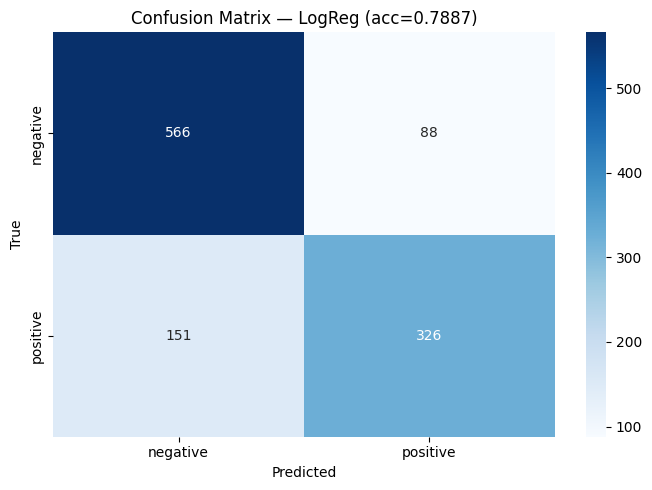


Всего ошибок: 239 из 1131 (21.1%)

---
TRUE: positive | PRED: negative | conf=0.55
TEXT: я считаю это мем года https://t.co/xoVKj5y8Mj
---
TRUE: positive | PRED: negative | conf=0.79
TEXT: ян русский на сотку все запятые где надо🤙🏻👍🏻👍🏻👍🏻👍🏻
я ещё сидел думал чо не так с этим твитом
---
TRUE: positive | PRED: negative | conf=0.73
TEXT: @Oppocum09 У нас в столовке лудшая греча с мясом
---
TRUE: positive | PRED: negative | conf=0.53
TEXT: @ineedanescap Волнуемся🤗
---
TRUE: positive | PRED: negative | conf=0.57
TEXT: Вот и чудно.
---
TRUE: positive | PRED: negative | conf=0.63
TEXT: @CulturalBaby ого они реально упомянули эспу
спасибо большое за перевод ты большая умничка🧡
---
TRUE: positive | PRED: negative | conf=0.56
TEXT: @boglaid ОНА ВЕРНЕЕЕЕТСЯЯЯЯЯЯЯЯЯЯЯ
---
TRUE: positive | PRED: negative | conf=0.87
TEXT: По словам разработчиков, эффективность российского препарата выше 80%.
---
TRUE: negative | PRED: positive | conf=0.58
TEXT: сначала арт для фавочки
потом арт с Сонхва

ту продакт

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# --- Confusion Matrix ---
cm = confusion_matrix(y_test_b, chosen_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['negative', 'positive'],
            yticklabels=['negative', 'positive'])
plt.title(f'Confusion Matrix — {chosen_name} (acc={accuracy_score(y_test_b, chosen_pred):.4f})')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

# --- Топ-20 ошибочных примеров ---
CLASS_NAMES = {0: 'negative', 1: 'positive'}
mask = y_test_b != chosen_pred
idx = np.where(mask)[0]

print(f'\nВсего ошибок: {mask.sum()} из {len(y_test_b)} '
      f'({mask.sum()/len(y_test_b)*100:.1f}%)\n')

for i in idx[:20]:
    conf = chosen_proba[i].max()
    print('---')
    print(f'TRUE: {CLASS_NAMES[y_test_b[i]]} | '
          f'PRED: {CLASS_NAMES[chosen_pred[i]]} | conf={conf:.2f}')
    print(f'TEXT: {df_test_b["text"].iloc[i][:200]}')